# LAB | Whisper STT Implementation Lab

**Scenario:** You're working as an AI consultant for a company that needs to transcribe meeting recordings. Your client has hours of meeting audio that need to be converted to text with timestamps for easy reference and searchability. You'll use OpenAI's Whisper API to transcribe the audio, implement chunking for long recordings, and extract timestamps for each segment. This lab will teach you both guided (with prompts) and unguided (without prompts) transcription approaches.

What you'll build:

- Audio transcription system using Whisper API
- Chunking system for long audio files
- Timestamp extraction and formatting
- Comparison between prompted and unprompted transcriptions
- Export functionality for transcriptions

Why this matters: Speech-to-text is a fundamental AI capability used in:

- Meeting transcription and note-taking
- Accessibility features (captions, subtitles)
- Voice assistants and voice commands
- Content creation and podcast transcription
- Customer service call analysis

### Step 1: Setting Up the Environment


In [1]:
pip install openai pydub

Note: you may need to restart the kernel to use updated packages.


In [1]:
#pydub requires ffmpeg for audio procession - so i installed it !
import shutil
print(shutil.which("ffmpeg"))

None


In [2]:
%pip install sounddevice numpy librosa matplotlib scipy openai python-dotenv ipykernel

Note: you may need to restart the kernel to use updated packages.


In [3]:
import scipy.io.wavfile as wavfile
from openai import OpenAI
import io
import os
from IPython.display import Audio, display
from dotenv import load_dotenv

### Step 2: Downloading Sample Meeting Audio


did so manually

In [13]:
import os
import soundfile as sf

audio_path = "project_nimbus_meeting.mp3"
info = sf.info(audio_path)
print(info)  # prints everything at once
print("Duration (s):", info.duration)
print("Sample rate:", info.samplerate)
print("Channels:", info.channels)
print("Size (MB):", os.path.getsize(audio_path) / 1e6)


project_nimbus_meeting.mp3
samplerate: 22050 Hz
channels: 1
duration: 05:9.202 min
format: MPEG-1/2 Audio [MP3]
subtype: MPEG Layer III [MPEG_LAYER_III]
Duration (s): 309.2023129251701
Sample rate: 22050
Channels: 1
Size (MB): 2.474362


c:\Users\tscho\miniconda3\envs\bootcamp-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


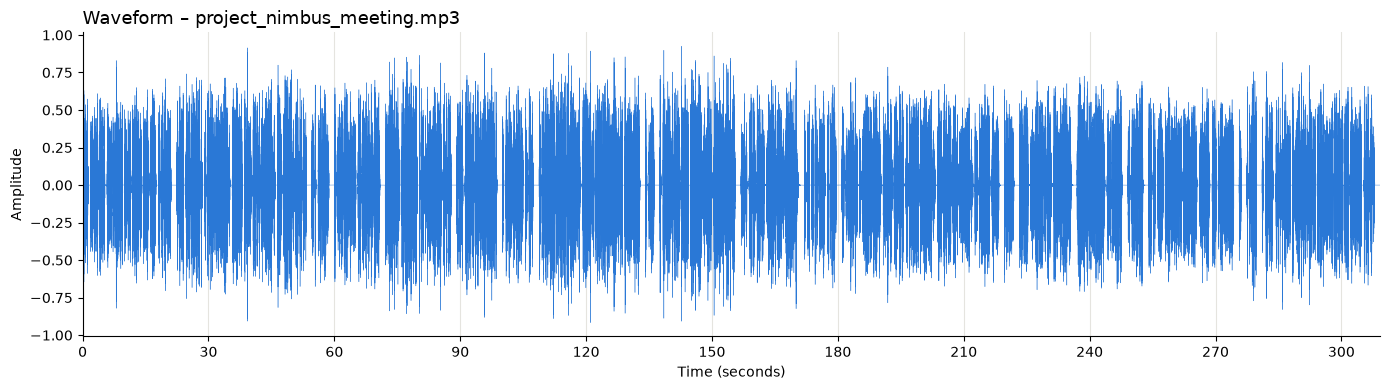

In [14]:
import numpy as np
import librosa
import matplotlib.pyplot as plt

audio_path = "project_nimbus_meeting.mp3"

# Load the audio: y = amplitude values, sr = sample rate (samples per second)
y, sr = librosa.load(audio_path, sr=None)  # sr=None keeps the original 22,050 Hz

# Build a time axis in seconds: sample number / samples per second
t = np.arange(len(y)) / sr

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(t, y, color="#2a78d6", linewidth=0.3)  # thin line: 6.8 million points

ax.set_title("Waveform – project_nimbus_meeting.mp3", loc="left", fontsize=13)
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Amplitude")
ax.set_xlim(0, t[-1])
ax.set_xticks(np.arange(0, t[-1], 30))           # a tick every 30 seconds
ax.grid(axis="x", color="#e5e4df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()


### Step 3: Basic Transcription (Without Chunking)

In [10]:
load_dotenv()
client = OpenAI(api_key=os.getenv("OPENAI_API_KEY"))
print("Key geladen:", os.getenv("OPENAI_API_KEY") is not None)

Key geladen: True


In [11]:
audio_path = "project_nimbus_meeting.mp3"

with open(audio_path, "rb") as f:        # "rb" = als Binärdatei öffnen
    transcript = client.audio.transcriptions.create(
        model="whisper-1",
        file=f,
        response_format="verbose_json",    # liefert zusätzlich Segmente mit Timestamps
    )

print(transcript.text)


Good morning everyone! This is the weekly engineering sync for Project Nimbus. Today is Thursday, and we have four items on the agenda. The Kubernetes migration, the PostgreSQL latency issue, the Q3 OKRs, and the hiring update. Priya, do you want to start with the migration? Sure, thanks Marcus. So the Kubernetes migration is about 70% done. We moved the authentication service, and the billing service to the new EKS cluster last week. The main blocker right now is the RIDIS cache. When we deployed it with Helm, the persistent volume claims were failing, because of a misconfigured storage class. I opened a ticket, JIRA number NIM-482, and I expect it to be fixed by Tuesday. Okay, good. Do we need anything from the DevOps team? Yes, we need Tomasz to approve the Terraform changes for the VPC peering. Without that, the pods in the staging namespace cannot reach the legacy database. I can review the Terraform pull request this afternoon. I saw it in GitHub yesterday, but I did not have tim

In [19]:
transcript 

TranscriptionVerbose(duration=309.20001220703125, language='english', text="Good morning everyone! This is the weekly engineering sync for Project Nimbus. Today is Thursday, and we have four items on the agenda. The Kubernetes migration, the PostgreSQL latency issue, the Q3 OKRs, and the hiring update. Priya, do you want to start with the migration? Sure, thanks Marcus. So the Kubernetes migration is about 70% done. We moved the authentication service, and the billing service to the new EKS cluster last week. The main blocker right now is the RIDIS cache. When we deployed it with Helm, the persistent volume claims were failing, because of a misconfigured storage class. I opened a ticket, JIRA number NIM-482, and I expect it to be fixed by Tuesday. Okay, good. Do we need anything from the DevOps team? Yes, we need Tomasz to approve the Terraform changes for the VPC peering. Without that, the pods in the staging namespace cannot reach the legacy database. I can review the Terraform pull 

In [20]:
for segment in transcript.segments:
    print(segment)

TranscriptionSegment(id=0, avg_logprob=-0.3078693747520447, compression_ratio=1.5110132694244385, end=5.800000190734863, no_speech_prob=0.04431701824069023, seek=0, start=0.0, temperature=0.0, text=' Good morning everyone! This is the weekly engineering sync for Project Nimbus.', tokens=[50364, 2205, 2446, 1518, 0, 639, 307, 264, 12460, 7043, 20271, 337, 9849, 426, 17306, 301, 13, 50654])
TranscriptionSegment(id=1, avg_logprob=-0.3078693747520447, compression_ratio=1.5110132694244385, end=9.920000076293945, no_speech_prob=0.04431701824069023, seek=0, start=5.800000190734863, temperature=0.0, text=' Today is Thursday, and we have four items on the agenda.', tokens=[50654, 2692, 307, 10383, 11, 293, 321, 362, 1451, 4754, 322, 264, 9829, 13, 50860])
TranscriptionSegment(id=2, avg_logprob=-0.3078693747520447, compression_ratio=1.5110132694244385, end=18.0, no_speech_prob=0.04431701824069023, seek=0, start=9.920000076293945, temperature=0.0, text=' The Kubernetes migration, the PostgreSQL l

### Step 4: Transcription with Prompts (Guided Approach)

### REMINDER: What the `prompt` does

- **What it is:** a few words Whisper treats as if they came *just before* the recording. It isn't an instruction like a ChatGPT prompt.
- **What it does:** when a sound is unclear, the prompt makes Whisper pick the right word and spelling.  
- **Why it matters:** in real projects, the prompt is where you put a client's product names, people's names and industry terms.

In [22]:
# Step 4: Guided transcription with a prompt

# The prompt is written like a piece of the meeting itself, not like an instruction.
# It contains the names and technical terms we expect, spelled correctly.
guided_prompt = (
    "Project Nimbus weekly engineering sync with Marcus, Priya, Tomasz and Aisha. "
    "Topics: Kubernetes migration to EKS, Redis cache, Helm, Terraform, VPC peering, "
    "t3.large and Graviton instances, PostgreSQL latency, EXPLAIN ANALYZE, "
    "customer_id and created_at, Alembic, pg_stat_statements, Datadog, NPS score, "
    "Q3 OKRs, Pinecone, SOC 2 Type II, CloudWatch, S3, Glacier, gRPC, Greenhouse."
)

with open(audio_path, "rb") as f:
    transcript_guided = client.audio.transcriptions.create(
        model="whisper-1",
        file=f,
        response_format="verbose_json",  # keep the timestamps
        prompt=guided_prompt,            # the new part
    )

print(transcript_guided.text)


Good morning everyone! This is the weekly engineering sync for Project Nimbus. Today is Thursday, and we have four items on the agenda. The Kubernetes migration, the PostgreSQL latency issue, the Q3 OKRs, and the hiring update. Priya, do you want to start with the migration? Sure, thanks Marcus. So the Kubernetes migration is about 70% done. We moved the authentication service, and the billing service to the new EKS cluster last week. The main blocker right now is the Redis cache. When we deployed it with Helm, the persistent volume claims were failing, because of a misconfigured storage class. I opened a ticket, JIRA number NIM-482, and I expect it to be fixed by Tuesday. OK, good. Do we need anything from the DevOps team? Yes, we need Tomasz to approve the Terraform changes for the VPC peering. Without that, the pods in the staging namespace cannot reach the legacy database. I can review the Terraform pull request this afternoon. I saw it in GitHub yesterday, but I did not have time.

In [23]:
# Unguided result = your cell 13 output (the variable `transcript`)
with open("transcript_unguided.txt", "w", encoding="utf-8") as f:
    f.write(transcript.text)

with open("transcript_guided.txt", "w", encoding="utf-8") as f:
    f.write(transcript_guided.text)

print("Saved both transcripts.")


Saved both transcripts.


In [24]:
import difflib

unguided_words = transcript.text.split()
guided_words = transcript_guided.text.split()

matcher = difflib.SequenceMatcher(None, unguided_words, guided_words)
for tag, i1, i2, j1, j2 in matcher.get_opcodes():
    if tag != "equal":
        print(f"WITHOUT prompt: {' '.join(unguided_words[i1:i2]):35} | WITH prompt: {' '.join(guided_words[j1:j2])}")


WITHOUT prompt: RIDIS                               | WITH prompt: Redis
WITHOUT prompt: Okay,                               | WITH prompt: OK,
WITHOUT prompt: Xplane Analyze on the slow          | WITH prompt: xplane-analyze on the sloke
WITHOUT prompt: pgstat                              | WITH prompt: PGstat
WITHOUT prompt: Datadog                             | WITH prompt: metadog
WITHOUT prompt: MPS                                 | WITH prompt: NPS
WITHOUT prompt: Okay,                               | WITH prompt: OK,
WITHOUT prompt: database we chose,                  | WITH prompt: database, we chose
WITHOUT prompt: SoC                                 | WITH prompt: SOC
WITHOUT prompt: SoC                                 | WITH prompt: SOC
WITHOUT prompt: 1                                   | WITH prompt: one
WITHOUT prompt: Go                                  | WITH prompt: Go,


### Step 6: Implementing Audio Chunking

The Whisper API accepts files up to **25 MB**. Long meeting recordings are bigger, so we cut the audio into smaller pieces ("chunks") and transcribe each one separately.

Our file is only 2.5 MB / 5 min, so chunking isn't strictly needed here. To practise the technique we use **60-second chunks** (10-minute chunks would give us just one). librosa + soundfile are used instead of pydub, because they don't need ffmpeg.

In [26]:
import os
import librosa
import soundfile as sf

audio_path = "project_nimbus_meeting.mp3"
chunk_seconds = 60                      # length of each chunk

y, sr = librosa.load(audio_path, sr=None)   # all audio samples + sample rate
samples_per_chunk = chunk_seconds * sr      # 60 s × 22,050 = 1,323,000 samples

os.makedirs("chunks", exist_ok=True)
chunks = []   # list of (file path, start time in seconds)

for i, start_sample in enumerate(range(0, len(y), samples_per_chunk)):
    chunk_audio = y[start_sample : start_sample + samples_per_chunk]   # slice the array
    path = f"chunks/chunk_{i:02d}.wav"
    sf.write(path, chunk_audio, sr)                                     # save as WAV
    start_time = start_sample / sr                                      # samples → seconds
    chunks.append((path, start_time))
    print(f"{path}: starts at {start_time:5.0f}s, length {len(chunk_audio)/sr:5.1f}s, "
          f"size {os.path.getsize(path)/1e6:.1f} MB")


chunks/chunk_00.wav: starts at     0s, length  60.0s, size 2.6 MB
chunks/chunk_01.wav: starts at    60s, length  60.0s, size 2.6 MB
chunks/chunk_02.wav: starts at   120s, length  60.0s, size 2.6 MB
chunks/chunk_03.wav: starts at   180s, length  60.0s, size 2.6 MB
chunks/chunk_04.wav: starts at   240s, length  60.0s, size 2.6 MB
chunks/chunk_05.wav: starts at   300s, length   9.2s, size 0.4 MB


### Step 7: Transcribing Chunks with Timestamps

1. **Transcribe each chunk**: loop over the chunk files and send each to Whisper with `response_format="verbose_json"`, which returns segments with `start` / `end` times. No prompt is used, so this is the unguided approach.
2. **Adjust timestamps for the chunk offset**: Whisper only sees its own chunk, so every chunk's timestamps start at 0. A segment at 0:12 inside `chunk_02` (which starts at 120 s) really happens at 120 + 12 = **2:12**. So we add the chunk's start time to every `start` and `end`.
3. **Combine**: all corrected segments go into one list, `all_segments`, in order, so the result reads like one transcript of the whole file.
4. **Export with timestamps**: each segment is written as `[mm:ss – mm:ss] text` to `transcript_unguided_chunked.txt`.

In [27]:
#trascribe each chunk witout a promt, fix timestamps and combine:

all_segments = []   # every segment from every chunk, with corrected timestamps

for path, offset in chunks:
    with open(path, "rb") as f:
        result = client.audio.transcriptions.create(
            model="whisper-1",
            file=f,
            response_format="verbose_json",   # we need the segments with timestamps
            # no prompt → unguided
        )
    print(f"Transcribed {path} ({len(result.segments)} segments)")

    for seg in result.segments:
        all_segments.append({
            "start": seg.start + offset,   # ← the key step: shift by the chunk's start time
            "end": seg.end + offset,
            "text": seg.text.strip(),
        })

full_text_chunked = " ".join(s["text"] for s in all_segments)


Transcribed chunks/chunk_00.wav (10 segments)
Transcribed chunks/chunk_01.wav (14 segments)
Transcribed chunks/chunk_02.wav (9 segments)
Transcribed chunks/chunk_03.wav (10 segments)
Transcribed chunks/chunk_04.wav (10 segments)
Transcribed chunks/chunk_05.wav (2 segments)


In [28]:
def fmt(seconds):
    m, s = divmod(int(seconds), 60)
    return f"{m:02d}:{s:02d}"

with open("transcript_unguided_chunked.txt", "w", encoding="utf-8") as f:
    for s in all_segments:
        line = f"[{fmt(s['start'])} – {fmt(s['end'])}] {s['text']}"
        print(line)
        f.write(line + "\n")


[00:00 – 00:05] Good morning everyone! This is the weekly engineering sync for Project Nimbus.
[00:05 – 00:09] Today is Thursday, and we have four items on the agenda.
[00:09 – 00:18] The Kubernetes migration, the PostgreSQL latency issue, the Q3 OKRs, and the hiring update.
[00:18 – 00:22] Priya, do you want to start with the migration?
[00:22 – 00:28] Sure, thanks Marcus. So the Kubernetes migration is about 70% done.
[00:28 – 00:35] We moved the authentication service, and the billing service to the new EKS cluster last week.
[00:35 – 00:38] The main blocker right now is the RIDIS cache.
[00:38 – 00:46] When we deployed it with Helm, the persistent volume claims were failing, because of a misconfigured storage class.
[00:46 – 00:54] I opened a ticket, Jira number NIM-482, and I expect it to be fixed by Tuesday.
[00:54 – 01:00] Okay, good. Do we need anything from the DevOps team?
[01:00 – 01:05] Yes, we need Tomasz to approve the Terraform changes for the VPC peering.
[01:05 – 01:12

In [ ]:
# Checkpoint: verify that the combined timestamps are correct

starts = [s["start"] for s in all_segments]
audio_duration = len(y) / sr

# 1. Times must only go forward. If the offset were missing, they would jump back to 0 at every new chunk.
print("Timestamps always increase:", all(b >= a for a, b in zip(starts, starts[1:])))

# 2. The last segment must end close to the real length of the audio.
print(f"Last segment ends at {all_segments[-1]['end']:.1f}s | audio length {audio_duration:.1f}s")

# 3. Show the segments around each cut point, to check that the offset was applied there.
for path, offset in chunks[1:]:
    first = next(s for s in all_segments if s["start"] >= offset)
    print(f"First segment after the cut at {fmt(offset)}: [{fmt(first['start'])}] {first['text'][:50]}")

### Step 5: Transcription Without Prompts (Unguided Approach) – Comparison

The unguided transcription without chunking is the result from Step 3 (`transcript`); the unguided transcription with chunking is the result from Step 7. Here all three versions are compared:

- **unguided**: no prompt, no chunking (Step 3)
- **guided**: with prompt, no chunking (Step 4)
- **chunked**: no prompt, with 60-second chunks (Step 7)

Two measures are used: overall word similarity (`difflib`) and a count of key technical terms in each version.

In [29]:
import re
import difflib

unguided = open("transcript_unguided.txt", encoding="utf-8").read()
guided = open("transcript_guided.txt", encoding="utf-8").read()
with open("transcript_unguided_chunked.txt", encoding="utf-8") as f:
    chunked = " ".join(re.sub(r"^\[[^\]]*\]\s*", "", line) for line in f.read().splitlines())

versions = {"unguided": unguided, "guided": guided, "chunked": chunked}

# 1. Overall similarity between each pair
for a, b in [("unguided", "guided"), ("unguided", "chunked"), ("guided", "chunked")]:
    ratio = difflib.SequenceMatcher(None, versions[a].split(), versions[b].split()).ratio()
    print(f"{a:9} vs {b:8}: {ratio:.1%} identical")

# 2. Key terms in all three versions
for term in ["Redis", "RIDIS", "Datadog", "metadog", "NPS", "MPS", "SOC 2", "Pinecone", "Xplane"]:
    print(f"{term:10}", {name: text.count(term) for name, text in versions.items()})


unguided  vs guided  : 97.3% identical
unguided  vs chunked : 93.4% identical
guided    vs chunked : 93.9% identical
Redis      {'unguided': 1, 'guided': 2, 'chunked': 1}
RIDIS      {'unguided': 1, 'guided': 0, 'chunked': 1}
Datadog    {'unguided': 1, 'guided': 0, 'chunked': 0}
metadog    {'unguided': 0, 'guided': 1, 'chunked': 1}
NPS        {'unguided': 0, 'guided': 1, 'chunked': 1}
MPS        {'unguided': 1, 'guided': 0, 'chunked': 0}
SOC 2      {'unguided': 0, 'guided': 2, 'chunked': 2}
Pinecone   {'unguided': 2, 'guided': 2, 'chunked': 1}
Xplane     {'unguided': 1, 'guided': 0, 'chunked': 0}


Prompted vs. unprompted: 97% identical. The prompt reliably fixed "Redis". Other changes (NPS, SOC 2, "metadog") also appeared in a run without a prompt, so they are likely random run-to-run variation rather than an effect of the prompt.

Chunked vs. unchunked: 93% identical, a larger change than the prompt made. The serious new errors all fall on the 60-second cut points (02:00 "Ironic, ple-", 04:00 "live site.", 05:00 "Priya" lost), because words were cut in half. Chunks also lose style consistency (ms → milliseconds, 3 → three).

Conclusion: chunk only when the file is over 25 MB, and if you do, cut at silences instead of fixed times. Prompts help with specific names and terms but don't guarantee correct spelling.

### Step 8: Exporting with Timestamps

The same segments are exported in three formats, because each has a different user:

| Format | For whom | Why |
|---|---|---|
| **.txt** `[hh:mm:ss - hh:mm:ss] text` | people | easy to read, search (Ctrl+F) and jump to a moment in the meeting |
| **.srt** | video players (VLC, YouTube, Teams…) | standard subtitle format, shows text in sync with the recording |
| **.json** | other programs | structured data with exact times, e.g. for a search index, a database or an LLM summary |

All three are built from one list of segments (`start`, `end`, `text`), so one function can export any transcript. It is used for the chunked transcript (Step 7) and the guided one (Step 4).

In [ ]:
import json
import os

def readable_time(seconds):
    """3725.4 -> '01:02:05' (hours included, so it also works for long meetings)"""
    h, rest = divmod(int(seconds), 3600)
    m, s = divmod(rest, 60)
    return f"{h:02d}:{m:02d}:{s:02d}"

def srt_time(seconds):
    """3725.123 -> '01:02:05,123' (SRT needs milliseconds and a comma)"""
    ms = round(seconds * 1000)
    h, ms = divmod(ms, 3_600_000)
    m, ms = divmod(ms, 60_000)
    s, ms = divmod(ms, 1000)
    return f"{h:02d}:{m:02d}:{s:02d},{ms:03d}"

def export_transcript(segments, base_name, source_file):
    """Write segments (list of dicts with start, end, text) as .txt, .srt and .json."""
    # 1. Human-readable text
    with open(f"{base_name}.txt", "w", encoding="utf-8") as f:
        for seg in segments:
            f.write(f"[{readable_time(seg['start'])} - {readable_time(seg['end'])}] {seg['text']}\n")

    # 2. SRT subtitles: number, time range, text, blank line
    with open(f"{base_name}.srt", "w", encoding="utf-8") as f:
        for i, seg in enumerate(segments, start=1):
            f.write(f"{i}\n{srt_time(seg['start'])} --> {srt_time(seg['end'])}\n{seg['text']}\n\n")

    # 3. JSON: metadata + all segments
    data = {
        "source_file": source_file,
        "segment_count": len(segments),
        "duration_seconds": round(segments[-1]["end"], 2),
        "segments": [
            {"id": i, "start": round(s["start"], 2), "end": round(s["end"], 2), "text": s["text"]}
            for i, s in enumerate(segments)
        ],
    }
    with open(f"{base_name}.json", "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2, ensure_ascii=False)   # ensure_ascii=False keeps ä, ö, ü readable

    print(f"Exported {len(segments)} segments to {base_name}.txt / .srt / .json")


os.makedirs("exports", exist_ok=True)

# Chunked transcript from Step 7 (already a list of dicts)
export_transcript(all_segments, "exports/nimbus_chunked", audio_path)

# Guided transcript from Step 4 (segment objects -> convert to dicts first)
guided_segments = [{"start": s.start, "end": s.end, "text": s.text.strip()} for s in transcript_guided.segments]
export_transcript(guided_segments, "exports/nimbus_guided", audio_path)

In [ ]:
# Checkpoint: look at the beginning of each exported file
for ext in ("txt", "srt", "json"):
    with open(f"exports/nimbus_chunked.{ext}", encoding="utf-8") as f:
        print(f"===== nimbus_chunked.{ext} =====")
        print(f.read()[:350], "...\n")

# The JSON must load back without errors
with open("exports/nimbus_chunked.json", encoding="utf-8") as f:
    loaded = json.load(f)
print("JSON valid,", loaded["segment_count"], "segments,", loaded["duration_seconds"], "s")